# Post-run EDA of `80K-earlymule-mule`

EMTG-69. The first EDA (`01_amlsim_eda.ipynb`) checked feasibility on the old 10K run, before AMLSim was modified. This notebook looks at the dataset the models are now trained on, with the 72 point-in-time features, and at what the trained models miss. The advisor's questions behind it (2026-11-15): which features identify a mule account, and how much time a bank has between a mule's onset and its first forwarding.

Sections: 1 overview · 2 mule timelines · 3 features at the decision point · 4 trajectories around onset and first outflow · 5 redundancy · 6 simulator shortcuts · 7 what the models miss. Figures and tables go to `reports/figures/eda/`; the summary with numbers is `reports/post_run_eda.md`.

Conventions: day index with end-of-day cut-off; `seq` = execution order within a day (`earlymule.data.intraday_order`). The scored population is the regular accounts (at least 20 transfers up to the day). Labels are used here for analysis only.

In [1]:
# Setup: inputs of the configured dataset, ground truth, labelled transfers, output folder
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt   # inline backend: each figure shows under its cell
from IPython.display import display
from earlymule.config import load_paths, repo_root
from earlymule.data import amlsim
from earlymule.models.tabular import load_inputs, load_config
from earlymule.analysis import eda

pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
ROOT = repo_root(); FIG = ROOT / 'reports' / 'figures' / 'eda'; FIG.mkdir(parents=True, exist_ok=True)
paths = load_paths(); base = amlsim.read_base_date(paths.amlsim_conf)
cfg = load_config('daily.yaml'); WINDOWS = tuple(cfg['windows']); EXCLUDE = cfg['exclude_features']
inputs = load_inputs(); tx = eda.labelled_transfers(paths.dataset_dir, base)
gt = pd.read_parquet(ROOT / 'data' / 'processed' / 'ground_truth.parquet')
mules, members = inputs['mules'], pd.Index(gt.acct_id.unique())
regular_from = eda.regular_accounts(inputs['tx'], cfg['regular_min_tx'])
rng = np.random.default_rng(0)
summary = {}   # headline numbers, written to reports/figures/eda/summary.json at the end
print(len(tx), 'transfers;', len(mules), 'mules;', len(members), 'case members')

1789235 transfers; 942 mules; 3531 case members


## 1. Overview

accounts                96344
active accounts         31560
regular at day 719      15416
transfers             1789235
illicit transfers        3059


,cases,mules
typology,,
mule_fan_in_out,150,150
mule_collect_exit,150,150
mule_relay_chain,50,151
mule_collect_disperse,50,170
cycle,40,321
fan_in,30,0
fan_out,30,0


,non-mule members
role,
source,1467
destination,1050
collector,30
disperser,30
no_illicit,12


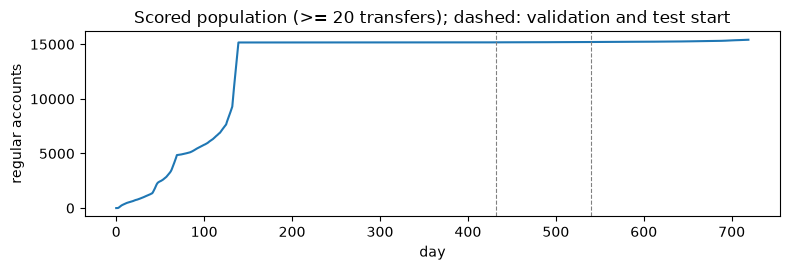

In [2]:
# Accounts, activity, cases and mules by typology; size of the scored population over time
active = pd.Index(np.union1d(tx.orig_acct, tx.bene_acct))
case_typ = gt.drop_duplicates('alert_id').typology.value_counts().rename('cases')
mule_typ = mules.typology.value_counts().rename('mules')
role_other = gt[~gt.is_mule_candidate].role.value_counts().rename('non-mule members')
print(pd.Series({'accounts': len(inputs['accounts']), 'active accounts': len(active),
                 'regular at day 719': int((regular_from <= 719).sum()), 'transfers': len(tx),
                 'illicit transfers': int(tx.is_sar.sum())}).to_string())
display(pd.concat([case_typ, mule_typ], axis=1).fillna(0).astype(int)); display(role_other.to_frame())
days = np.arange(720)
reg_count = np.searchsorted(np.sort(regular_from.to_numpy()), days, side='right')
fig, ax = plt.subplots(figsize=(8, 2.8)); ax.plot(days, reg_count)
for d in (432, 540): ax.axvline(d, color='grey', ls='--', lw=0.8)
ax.set(xlabel='day', ylabel='regular accounts', title='Scored population (>= 20 transfers); dashed: validation and test start')
fig.tight_layout(); fig.savefig(FIG / 'regular_population.png', dpi=150)
summary.update(accounts=len(inputs['accounts']), active=len(active), regular_end=int(reg_count[-1]), mules=len(mules))

## 2. Mule timelines

For each mule: onset (first illicit transfer either way), first illicit outflow, completion. The gap between onset and first outflow is the time a bank has to stop the money before it moves on. Same-day mules are split by execution order: receives first (catchable only when a transfer is scored before it is executed) or forwards first (the cycle initiators).

,mules,median_days_to_first_out,same_day,one_day,median_case_days,median_forwarded_share
typology,,,,,,
cycle,321,1.0,0.393,0.252,1.0,0.955
mule_collect_disperse,170,2.0,0.218,0.265,2.0,0.900
mule_collect_exit,150,4.0,0.013,0.073,4.0,0.900
mule_fan_in_out,150,3.0,0.047,0.127,5.0,0.900
mule_relay_chain,151,1.0,0.331,0.371,1.0,0.900


,count
same_day_order,
different days,720
receives first,182
forwards first,40


,count,mean,std,min,25%,50%,75%,max
days_to_first_out,942.0,2.27,2.25,0.0,1.0,2.0,3.0,14.0


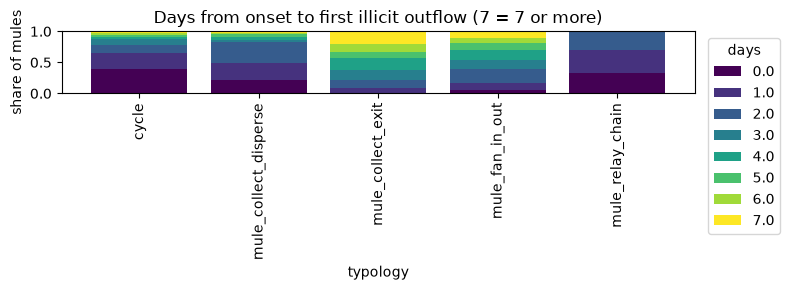

In [3]:
# Timeline per mule and its summary by typology
tl = eda.mule_timeline(mules, tx)
by = tl.groupby('typology').agg(mules=('onset_day', 'size'), median_days_to_first_out=('days_to_first_out', 'median'),
                                same_day=('days_to_first_out', lambda s: (s == 0).mean()),
                                one_day=('days_to_first_out', lambda s: (s == 1).mean()),
                                median_case_days=('case_days', 'median'),
                                median_forwarded_share=('forwarded_share', 'median'))
display(by.round(3)); display(tl.same_day_order.value_counts().to_frame())
display(tl.days_to_first_out.describe().round(2).to_frame().T)
gap = tl.days_to_first_out.clip(upper=7)
tab = pd.crosstab(tl.typology, gap, normalize='index')
fig, ax = plt.subplots(figsize=(8, 3)); tab.plot.bar(stacked=True, ax=ax, colormap='viridis', width=0.8)
ax.set(ylabel='share of mules', title='Days from onset to first illicit outflow (7 = 7 or more)')
ax.legend(title='days', bbox_to_anchor=(1.01, 1), loc='upper left'); fig.tight_layout(); fig.savefig(FIG / 'days_to_first_outflow.png', dpi=150)
by.to_csv(FIG / 'timeline_by_typology.csv')
summary.update(gap_median=float(tl.days_to_first_out.median()), same_day=float((tl.days_to_first_out == 0).mean()),
               one_day=float((tl.days_to_first_out == 1).mean()),
               same_day_order=tl.same_day_order.value_counts().to_dict())

## 3. Features at the decision point

End-of-day scoring can stop a mule only on the days before its first outflow, so the decision point is the end of day (first outflow − 1), for mules with at least one day between onset and first outflow and in the scored population by then. The comparison group is 30 random regular accounts outside every case on each of those days, i.e. the accounts the mule competes with for an alert. Single-feature ROC-AUC, KS and PR-AUC show how much each feature separates on its own.

620 mules, 11760 controls, 73 features


,feature,family,median_mule,median_other,missing_mule,missing_other,smd,roc_auc,ks,pr_auc,separation
0,new_share_in_7d,churn,1.000,0.000,0.005,0.696,2.557,0.967,0.770,0.639,0.467
1,new_peers_in_7d,churn,1.000,0.000,0.000,0.000,1.412,0.940,0.880,0.351,0.440
2,n_in_7d_over_30d,cross_window,1.000,0.207,0.000,0.583,1.945,0.939,0.707,0.491,0.439
3,new_share_in_30d,churn,1.000,0.000,0.000,0.583,1.742,0.930,0.615,0.369,0.430
4,days_since_last_in,recency,0.000,7.000,0.000,0.379,-0.723,0.097,0.617,0.224,0.403
5,new_peers_in_30d,churn,1.000,0.000,0.000,0.000,0.430,0.886,0.789,0.187,0.386
6,amt_in_7d_over_30d,cross_window,1.000,0.199,0.000,0.583,1.631,0.879,0.576,0.440,0.379
7,peers_in_7d,fan,2.000,0.000,0.000,0.000,0.444,0.860,0.691,0.151,0.360
8,n_in_7d,activity,2.000,0.000,0.000,0.000,0.412,0.855,0.691,0.147,0.355
9,peers_in_7d_over_30d,cross_window,1.000,0.483,0.000,0.583,1.182,0.826,0.464,0.201,0.326


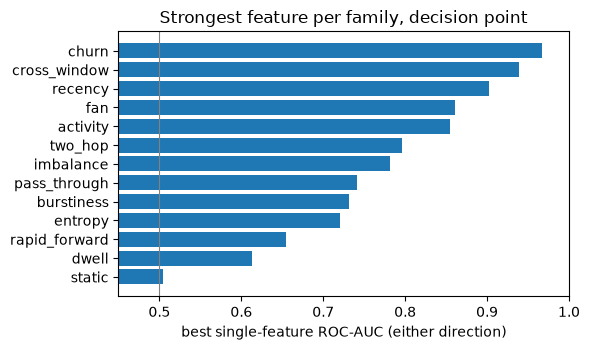

In [4]:
# Decision rows: mules at end of day (first outflow - 1) and random regular non-members on the same days
dec = tl[(tl.days_to_first_out >= 1)].assign(day=lambda t: (t.first_illicit_outflow_day - 1).astype(int))
dec = dec[regular_from.reindex(dec.index).le(dec.day).fillna(False).to_numpy()]
ctrl = eda.sample_controls(dec.day.to_numpy(), regular_from, members, 30, rng)
rows = pd.concat([pd.DataFrame({'acct_id': dec.index, 'day': dec.day.to_numpy(), 'is_mule': True,
                                'typology': dec.typology.to_numpy()}),
                  ctrl.assign(is_mule=False, typology=None)], ignore_index=True)
X = eda.features_for_rows(inputs, rows, WINDOWS, EXCLUDE)
FEATS = [c for c in X.columns if c not in ('acct_id', 'day', 'is_mule', 'typology')]
uni = eda.univariate_table(X, FEATS)
uni.to_csv(FIG / 'univariate_decision_point.csv', index=False)
print(int(X.is_mule.sum()), 'mules,', int((~X.is_mule).sum()), 'controls,', len(FEATS), 'features')
display(uni.head(25).round(3))
fam = uni.groupby('family').separation.max().sort_values()
fig, ax = plt.subplots(figsize=(6, 3.6)); ax.barh(fam.index, fam.values + 0.5)
ax.axvline(0.5, color='grey', lw=0.8); ax.set(xlabel='best single-feature ROC-AUC (either direction)', xlim=(0.45, 1),
       title='Strongest feature per family, decision point'); fig.tight_layout(); fig.savefig(FIG / 'family_best_auc.png', dpi=150)
summary['decision_rows'] = {'mules': int(X.is_mule.sum()), 'controls': int((~X.is_mule).sum())}
summary['top_features'] = uni.head(10)[['feature', 'roc_auc', 'ks']].round(3).to_dict('records')
summary['family_best_auc'] = (fam + 0.5).round(3).to_dict()

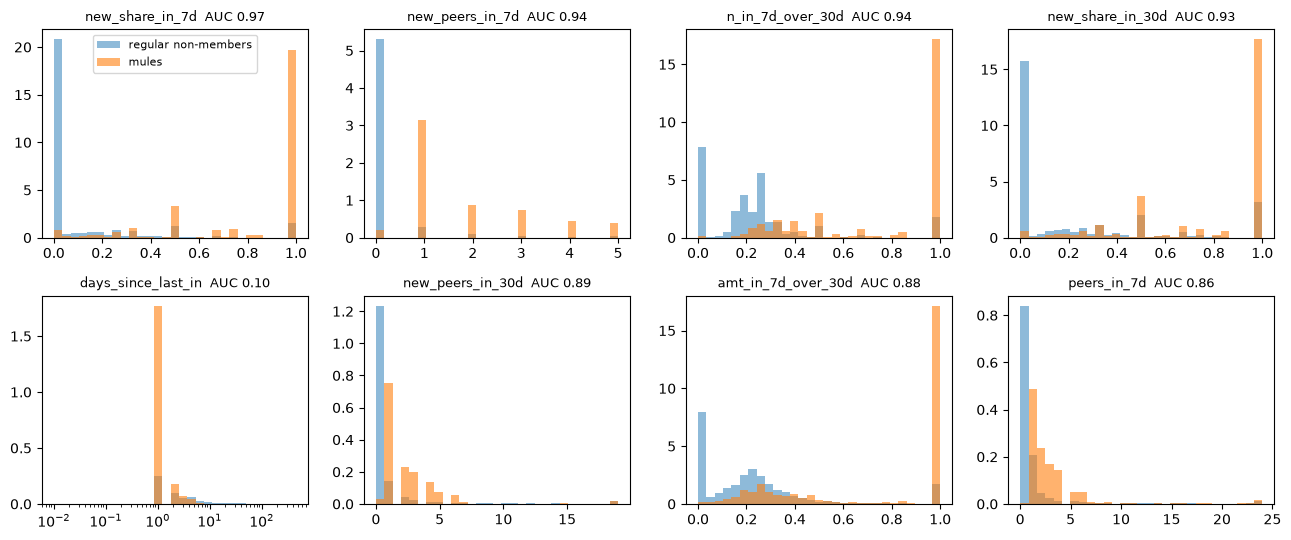

In [5]:
# Distributions of the eight strongest features, mules against controls (log scale for skewed positives)
top = uni.feature.head(8).tolist()
fig, axes = plt.subplots(2, 4, figsize=(13, 5.5))
for ax, c in zip(axes.flat, top):
    a, b = X.loc[X.is_mule, c].dropna(), X.loc[~X.is_mule, c].dropna()
    lo, hi = np.nanpercentile(pd.concat([a, b]), [1, 99])
    log = lo >= 0 and hi > 50
    bins = np.logspace(np.log10(max(lo, 1e-2)), np.log10(hi + 1), 30) if log else np.linspace(lo, hi + 1e-9, 30)
    ax.hist(b.clip(lo, hi), bins=bins, density=True, alpha=0.5, label='regular non-members')
    ax.hist(a.clip(lo, hi), bins=bins, density=True, alpha=0.6, label='mules')
    if log: ax.set_xscale('log')
    ax.set_title(f"{c}  AUC {uni.set_index('feature').roc_auc[c]:.2f}", fontsize=9)
axes.flat[0].legend(fontsize=8); fig.tight_layout(); fig.savefig(FIG / 'top_feature_distributions.png', dpi=150)

In [6]:
# Univariate separation per typology: best three features for each
per_typ = []
for t, g in X[X.is_mule].groupby('typology'):
    u = eda.univariate_table(pd.concat([g, X[~X.is_mule]]), FEATS)
    per_typ.append(u.head(3).assign(typology=t, mules=len(g))[['typology', 'mules', 'feature', 'roc_auc', 'median_mule', 'median_other']])
per_typ = pd.concat(per_typ, ignore_index=True); display(per_typ.round(3))
per_typ.to_csv(FIG / 'univariate_by_typology.csv', index=False)

,typology,mules,feature,roc_auc,median_mule,median_other
0,cycle,160,new_share_in_7d,0.940,1.0,0.000
1,cycle,160,n_in_7d_over_30d,0.922,1.0,0.207
2,cycle,160,new_share_in_30d,0.921,1.0,0.000
3,mule_collect_disperse,121,new_share_in_7d,0.976,1.0,0.000
4,mule_collect_disperse,121,new_share_in_30d,0.944,1.0,0.000
5,mule_collect_disperse,121,n_in_7d_over_30d,0.944,1.0,0.207
6,mule_collect_exit,132,new_share_in_7d,0.981,1.0,0.000
7,mule_collect_exit,132,new_peers_in_7d,0.976,3.0,0.000
8,mule_collect_exit,132,n_in_7d_over_30d,0.959,1.0,0.207
9,mule_fan_in_out,123,new_share_in_7d,0.972,1.0,0.000


## 4. Trajectories around onset and first outflow

Each mule is followed from 14 days before onset to 7 days after its first outflow, next to 3 regular non-members of the same activity decile on its onset day, observed on the same calendar days. One feature per family is shown; the median and interquartile range per day offset.

In [7]:
# Feature trajectories: mules and matched controls on the same calendar days
ctrl_m = eda.matched_controls(tl, regular_from, eda.n_tx_up_to(inputs['tx']), members, 3, rng)
span = [(m, d) for m, r in tl.iterrows()
        for d in range(int(max(0, r.onset_day - 14)), int(min(719, r.first_illicit_outflow_day + 7)) + 1)]
mule_rows = pd.DataFrame(span, columns=['mule', 'day']).assign(acct_id=lambda f: f.mule, is_mule=True)
ctrl_rows = ctrl_m.merge(mule_rows[['mule', 'day']], on='mule').assign(is_mule=False)
traj = eda.features_for_rows(inputs, pd.concat([mule_rows, ctrl_rows], ignore_index=True), WINDOWS, EXCLUDE)
traj = traj.join(tl[['onset_day', 'first_illicit_outflow_day']], on='mule')
traj['from_onset'] = traj.day - traj.onset_day; traj['from_first_out'] = traj.day - traj.first_illicit_outflow_day
print(len(traj), 'rows;', traj.mule.nunique(), 'mules;', ctrl_m.acct_id.nunique(), 'control accounts')

90884 rows; 942 mules; 2413 control accounts


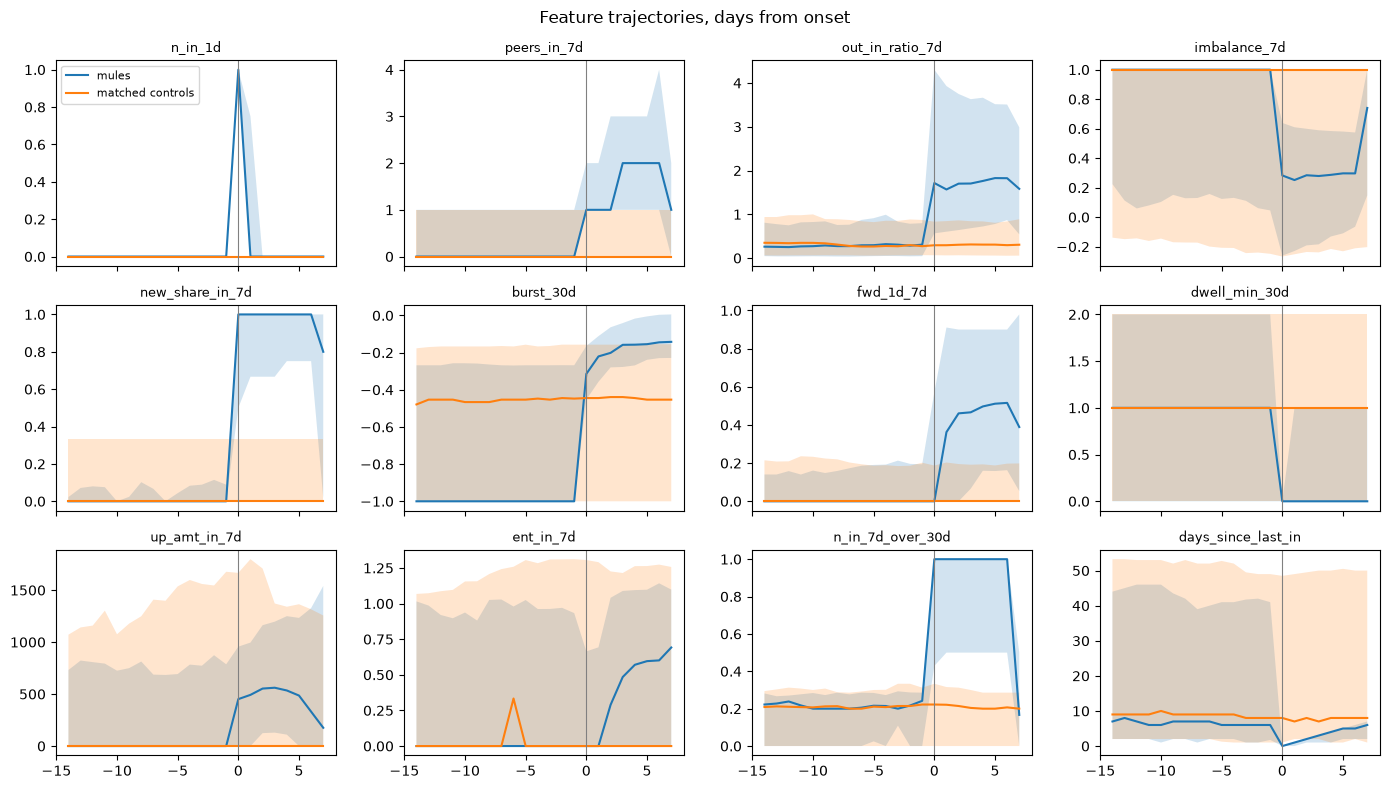

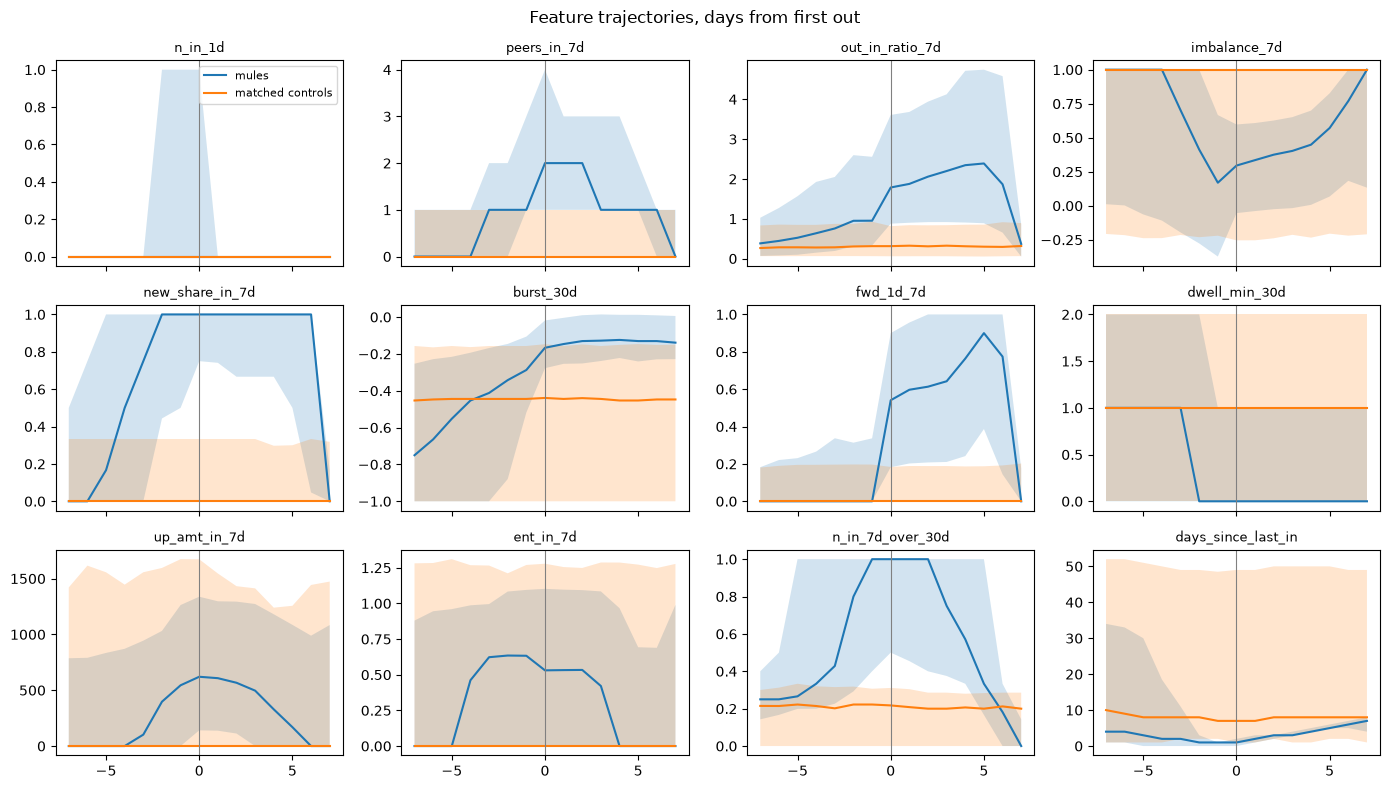

In [8]:
# Median and IQR by offset for one feature per family, aligned on onset and on first outflow
SHOW = ['n_in_1d', 'peers_in_7d', 'out_in_ratio_7d', 'imbalance_7d', 'new_share_in_7d', 'burst_30d',
        'fwd_1d_7d', 'dwell_min_30d', 'up_amt_in_7d', 'ent_in_7d', 'n_in_7d_over_30d', 'days_since_last_in']
for align, rng_ in [('from_onset', (-14, 7)), ('from_first_out', (-7, 7))]:
    sub = traj[traj[align].between(*rng_)]
    fig, axes = plt.subplots(3, 4, figsize=(14, 8), sharex=True)
    for ax, c in zip(axes.flat, SHOW):
        for flag, name in [(True, 'mules'), (False, 'matched controls')]:
            q = sub[sub.is_mule == flag].groupby(align)[c].quantile([0.25, 0.5, 0.75]).unstack()
            ax.plot(q.index, q[0.5], label=name); ax.fill_between(q.index, q[0.25], q[0.75], alpha=0.2)
        ax.axvline(0, color='grey', lw=0.8); ax.set_title(c, fontsize=9)
    axes.flat[0].legend(fontsize=8); fig.suptitle(f'Feature trajectories, days {align.replace("_", " ")}')
    fig.tight_layout(); fig.savefig(FIG / f'trajectories_{align}.png', dpi=150)

In [9]:
# Earliest day before first outflow at which mule and matched-control medians differ by 0.5 pooled SD (see the caveat below)
lead = []
s = traj[traj.from_first_out.between(-7, -1)]
for c in FEATS:
    g = s.groupby(['from_first_out', 'is_mule'])[c].median().unstack()
    sd = s[c].std()
    hit = g.index[(g[True] - g[False]).abs() > 0.5 * sd] if sd > 0 else []
    lead.append({'feature': c, 'family': eda.family_of(c), 'earliest_offset': int(min(hit)) if len(hit) else None})
lead = pd.DataFrame(lead).sort_values('earliest_offset'); display(lead.dropna().head(20))
lead.to_csv(FIG / 'feature_lead.csv', index=False)

,feature,family,earliest_offset
11,imbalance_1d,imbalance,-7.0
36,dwell_min_7d,dwell,-7.0
53,burst_30d,burstiness,-7.0
43,peers_out_30d,fan,-7.0
60,down_amt_out_30d,two_hop,-7.0
61,ent_out_30d,entropy,-7.0
65,peers_out_7d_over_30d,cross_window,-7.0
10,new_share_in_1d,churn,-6.0
66,peers_in_7d_over_30d,cross_window,-5.0
51,new_share_in_30d,churn,-4.0


The matched controls share the mule's activity decile, not its whole profile, so medians can differ before onset for reasons unrelated to the case (for example `burst_30d`, where about half of all regular accounts sit exactly at −1 and the median flips between groups). The check below compares mules three days before onset with random regular non-members on the same days: if no feature separates them there, every signal the models use appears at or after onset.

In [10]:
# Before onset: mules 3 days before their onset against random regular non-members on the same days
pre = tl.assign(day=(tl.onset_day - 3).clip(lower=30).astype(int))
pre = pre[regular_from.reindex(pre.index).to_numpy() <= pre.day.to_numpy()]
pre_rows = pd.concat([pd.DataFrame({'acct_id': pre.index, 'day': pre.day.to_numpy(), 'is_mule': True}),
                      eda.sample_controls(pre.day.to_numpy(), regular_from, members, 20, rng).assign(is_mule=False)],
                     ignore_index=True)
Xp = eda.features_for_rows(inputs, pre_rows, WINDOWS, EXCLUDE)
uni_pre = eda.univariate_table(Xp, FEATS); uni_pre.to_csv(FIG / 'univariate_before_onset.csv', index=False)
print(int(Xp.is_mule.sum()), 'mules,', int((~Xp.is_mule).sum()), 'controls; best ROC-AUC either way:',
      round(0.5 + uni_pre.separation.max(), 3))
display(uni_pre.head(8)[['feature', 'roc_auc', 'median_mule', 'median_other']].round(3))
summary['before_onset_best_auc'] = round(0.5 + float(uni_pre.separation.max()), 3)

804 mules, 8180 controls; best ROC-AUC either way: 0.515


,feature,roc_auc,median_mule,median_other
0,amt_out_7d_over_30d,0.515,0.239,0.230
1,up_amt_in_30d,0.486,2168.090,2588.310
2,peers_in_7d_over_30d,0.514,0.500,0.485
3,fwd_3d_30d,0.489,0.244,0.277
4,new_share_in_30d,0.489,0.000,0.000
5,n_out_7d_over_30d,0.511,0.250,0.250
6,dwell_med_7d,0.490,1.000,1.500
7,days_since_last_out,0.510,3.000,3.000


## 5. Redundancy

Features whose rank correlation exceeds 0.9 at the decision point (mules and controls together) are clustered; within a cluster, the feature with the best single-feature separation is the representative. Highly redundant clusters explain why removing one family may change little.

In [11]:
# Spearman clusters at |rho| > 0.9 and their representative feature
cl = eda.correlation_clusters(X, FEATS, 0.9)
red = uni.set_index('feature').join(cl).reset_index()
clusters = red.sort_values('separation', ascending=False).groupby('cluster').agg(
    size=('feature', 'size'), representative=('feature', 'first'), best_auc=('roc_auc', 'first'),
    members=('feature', lambda s: ', '.join(s)))
clusters = clusters.sort_values('size', ascending=False); display(clusters[clusters['size'] > 1])
print(cl.nunique(), 'clusters from', len(FEATS), 'features')
clusters.to_csv(FIG / 'correlation_clusters.csv'); summary['clusters'] = int(cl.nunique())

,size,representative,best_auc,members
cluster,,,,
36,5,imbalance_1d,0.269132,"imbalance_1d, out_in_ratio_1d, fwd_0d_1d, amt_..."
31,4,new_share_out_30d,0.495049,"new_share_out_30d, new_peers_out_7d, new_share..."
28,4,peers_in_7d,0.860355,"peers_in_7d, n_in_7d, amt_in_7d, ent_in_7d"
20,3,peers_out_30d,0.492523,"peers_out_30d, ent_out_30d, peers_out_7d_over_30d"
22,3,peers_in_1d,0.727296,"peers_in_1d, n_in_1d, amt_in_1d"
8,2,fwd_0d_7d,0.615746,"fwd_0d_7d, dwell_min_7d"
14,2,new_share_in_1d,0.740364,"new_share_in_1d, new_peers_in_1d"
15,2,new_share_in_7d,0.966861,"new_share_in_7d, new_peers_in_7d"
26,2,n_in_30d,0.745511,"n_in_30d, amt_in_30d"


48 clusters from 73 features


## 6. Simulator shortcuts

Regularities of the simulator that make some features stronger than they would be on real data (data spec, section 9): the forwarded share, the waiting time, illicit against normal amounts, how often regular accounts meet a new partner, and the size of the first illicit outflow against the balance before it.

In [12]:
# Forwarded share, illicit vs normal amounts, new partners, first outflow against balance
log = pd.read_csv(paths.dataset_dir / 'tx_log.csv', usecols=['oldbalanceOrig'])
first_out = tx[tx.is_sar].groupby('orig_acct').seq.min().reindex(mules.index).dropna().astype(int)
bal_before = log.oldbalanceOrig.to_numpy()[first_out.to_numpy() - 1]
amt = tx.set_index('seq').base_amt.reindex(first_out.to_numpy()).to_numpy()
layered = tl[tl.typology != 'cycle']
sc = pd.Series({
    'forwarded share, median (layered mules)': layered.forwarded_share.median(),
    'forwarded share within 0.89-0.91 (layered)': layered.forwarded_share.between(0.89, 0.91).mean(),
    'illicit amount, median': tx[tx.is_sar].base_amt.median(), 'normal amount, median': tx[~tx.is_sar].base_amt.median(),
    'first illicit outflow / balance before, median': np.median(amt / bal_before),
    'mules with a new partner in 7d at decision point': (X[X.is_mule].new_peers_in_7d.add(X[X.is_mule].new_peers_out_7d) > 0).mean(),
    'controls with a new partner in 7d': (X[~X.is_mule].new_peers_in_7d.add(X[~X.is_mule].new_peers_out_7d) > 0).mean()})
display(sc.round(3).to_frame('value')); summary['shortcuts'] = sc.round(4).to_dict()

,value
"forwarded share, median (layered mules)",0.900
forwarded share within 0.89-0.91 (layered),0.997
"illicit amount, median",155.540
"normal amount, median",549.820
"first illicit outflow / balance before, median",0.003
mules with a new partner in 7d at decision point,0.976
controls with a new partner in 7d,0.174


## 7. What the models miss

Per-mule test outcomes of the daily LightGBM with the 72 features (commit `7bfcfb4`, 3 seeds) and of the role-transition step (`tgn_transition`, same commit), at 10 new alerts per day with the 30-day cooldown. Misses are broken down by typology, days to first outflow and activity; alerts by what they land on.

In [13]:
# Detection before forwarding per mule, by typology, gap and activity, for both models
RUNS = {'LightGBM': 'lightgbm_daily', 'role transition': 'tgn_transition'}
det = []
for name, run in RUNS.items():
    for s in range(3):
        d = pd.read_parquet(ROOT / 'experiments' / 'runs' / run / '7bfcfb4' / f'seed{s}' / 'detection_test.parquet')
        det.append(d[d.k == 10].assign(model=name, seed=s))
det = pd.concat(det, ignore_index=True).join(tl[['days_to_first_out', 'same_day_order']], on='acct_id')
n_at = eda.n_tx_up_to(inputs['tx'])
act = pd.concat([n_at(int(d), pd.Index(g.index)) for d, g in tl.groupby('onset_day')])
det['activity_at_onset'] = pd.qcut(det.acct_id.map(act), 4, labels=['q1 low', 'q2', 'q3', 'q4 high'])
elig = det[det.can_precede_forwarding]
for col in ['typology', 'days_to_first_out', 'activity_at_onset']:
    display(elig.groupby([col, 'model'], observed=True).before_forwarding.mean().unstack().round(3))
both = elig.groupby(['acct_id', 'model']).before_forwarding.mean().unstack()
summary['eligible_test_mules'] = int(both.shape[0])
summary['never_caught_by_either'] = int(((both.fillna(0) == 0).all(axis=1)).sum())
summary['caught_by_lightgbm_typology'] = elig[elig.model == 'LightGBM'].groupby('typology').before_forwarding.mean().round(3).to_dict()
display(pd.crosstab(both['LightGBM'].round(2), both['role transition'].round(2), margins=True))

model,LightGBM,role transition
typology,,
cycle,0.583,0.625
mule_collect_disperse,0.929,0.905
mule_collect_exit,0.857,0.937
mule_fan_in_out,0.823,0.833
mule_relay_chain,0.869,0.838


model,LightGBM,role transition
days_to_first_out,,
1.0,0.772,0.813
2.0,0.846,0.816
3.0,0.788,0.939
4.0,0.850,0.900
5.0,1.000,1.000
6.0,0.889,0.852
7.0,0.667,0.778
8.0,0.800,0.800
9.0,1.000,1.000


model,LightGBM,role transition
activity_at_onset,,
q1 low,0.978,0.985
q2,0.936,0.979
q3,0.811,0.856
q4 high,0.591,0.561


role transition,0.0,0.33,0.67,1.0,All
LightGBM,,,,,
0.0,12,3,5,6,26
0.33,0,0,0,1,1
0.67,2,2,2,1,7
1.0,1,5,7,126,139
All,15,10,14,134,173


In [14]:
# Where the alerts go: active mules, mules outside their case days, other case members, other accounts
kinds = []
for name, run in RUNS.items():
    for s in range(3):
        sc_ = pd.read_parquet(ROOT / 'experiments' / 'runs' / run / '7bfcfb4' / f'seed{s}' / 'scores_test.parquet')
        a = eda.alert_outcomes(sc_, mules, inputs['other_members'], 10, 30)
        kinds.append(a.kind.value_counts(normalize=True).rename(f'{name} seed {s}'))
kinds = pd.concat(kinds, axis=1).fillna(0); display(kinds.round(3))
summary['alert_kinds'] = kinds.round(4).to_dict()
(FIG / 'summary.json').write_text(json.dumps(summary, indent=1, default=str))

,LightGBM seed 0,LightGBM seed 1,LightGBM seed 2,role transition seed 0,role transition seed 1,role transition seed 2
kind,,,,,,
other account,0.488,0.491,0.481,0.539,0.519,0.532
"case member, not mule",0.325,0.321,0.327,0.291,0.307,0.301
active mule,0.119,0.121,0.119,0.120,0.119,0.120
mule outside case days,0.068,0.067,0.073,0.051,0.054,0.047


3030